# Uber Rides — Advanced Analysis

> Structured workflow: **Data Loading → Validation → Feature Engineering → Analysis → Insights**

This notebook is a production-style refresh of the original project. It focuses on business-ready signals:
- **Demand peaks** (peak hours and peak days)
- **Efficiency metrics** (miles/min, duration distribution)
- **Category performance** (Business vs Personal)
- **Correlations** for drivers of cost/time
- **Anomalies** (unusually long/short trips)
- **Trends** (weekly/monthly) + a dashboard summary

In [10]:
# --- Setup (imports + plotting defaults) ---
from __future__ import annotations

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import project helpers from ./src
repo_root = Path.cwd()
src_path = repo_root / "src"
if src_path.exists() and str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

import importlib
import uber_analytics as ua
importlib.reload(ua)

from uber_analytics import (
    DAY_ORDER,
    add_features,
    compute_category_kpis,
    correlation_frame,
    detect_anomalies,
    detect_peaks,
    load_uber_data,
    monthly_weekly_trends,
    normalize_schema,
 )

sns.set_theme(style="whitegrid", context="talk")
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

In [2]:
# --- 1) Data Loading ---
df_raw = load_uber_data(prefer_cleaned=True)
df = add_features(normalize_schema(df_raw))

print("Rows, Columns:", df.shape)
display(df.head(5))

# --- 2) Lightweight validation ---
missing = df.isna().sum().sort_values(ascending=False).head(12)
display(missing.to_frame("missing"))

invalid = df[(df.get("duration", 1) <= 0) | (df.get("MILES", 1) < 0)]
print("Invalid trips (duration<=0 or miles<0):", len(invalid))

print("\nQuick note:")
print("- This notebook keeps invalid trips out of efficiency/anomaly metrics.")

Rows, Columns: (1141, 21)


,start_date,start_hour,start_minute,end_date,end_hour,end_minute,month,year,CATEGORY,START,...,MILES,PURPOSE,duration,speed,day,day_time,start_dt,miles_per_min,start_hour_int,is_weekend
0,2016-01-01,21.0,11.0,2016-01-01,21.0,17.0,Jan,2016,Business,Fort Pierce,...,8.207634,Meal/Entertain,6.0,82.076340,Friday,Evening,2016-01-01 21:11:00,1.367939,21,False
1,2016-01-02,1.0,25.0,2016-01-02,1.0,37.0,Jan,2016,Business,Fort Pierce,...,8.046700,Meal/Entertain,12.0,40.233500,Saturday,Night,2016-01-02 01:25:00,0.670558,1,True
2,2016-01-02,20.0,25.0,2016-01-02,20.0,38.0,Jan,2016,Business,Fort Pierce,...,7.724832,Errand/Supplies,13.0,35.653071,Saturday,Evening,2016-01-02 20:25:00,0.594218,20,True
3,2016-01-05,17.0,31.0,2016-01-05,17.0,45.0,Jan,2016,Business,Fort Pierce,...,7.563898,Meeting,14.0,32.416706,Tuesday,Afternoon,2016-01-05 17:31:00,0.540278,17,False
4,2016-01-06,14.0,42.0,2016-01-06,15.0,49.0,Jan,2016,Business,Fort Pierce,...,102.514958,Customer Visit,67.0,91.804440,Wednesday,Afternoon,2016-01-06 14:42:00,1.530074,14,False


,missing
miles_per_min,4
start_hour,0
start_minute,0
end_date,0
start_date,0
end_hour,0
end_minute,0
year,0
month,0
START,0


Invalid trips (duration<=0 or miles<0): 4

Quick note:
- This notebook keeps invalid trips out of efficiency/anomaly metrics.


,count,mean,std,min,10%,50%,90%,max
MILES,1137.0,16.246974,31.853653,0.804670,2.735878,9.495106,27.358780,499.378202
duration,1137.0,22.759015,25.074712,1.000000,6.000000,16.000000,41.000000,330.000000
miles_per_min,1137.0,0.715923,1.163225,0.105073,0.268223,0.560831,1.057566,24.301034
speed,1137.0,42.955362,69.793482,6.304357,16.093400,33.649836,63.453977,1458.062040


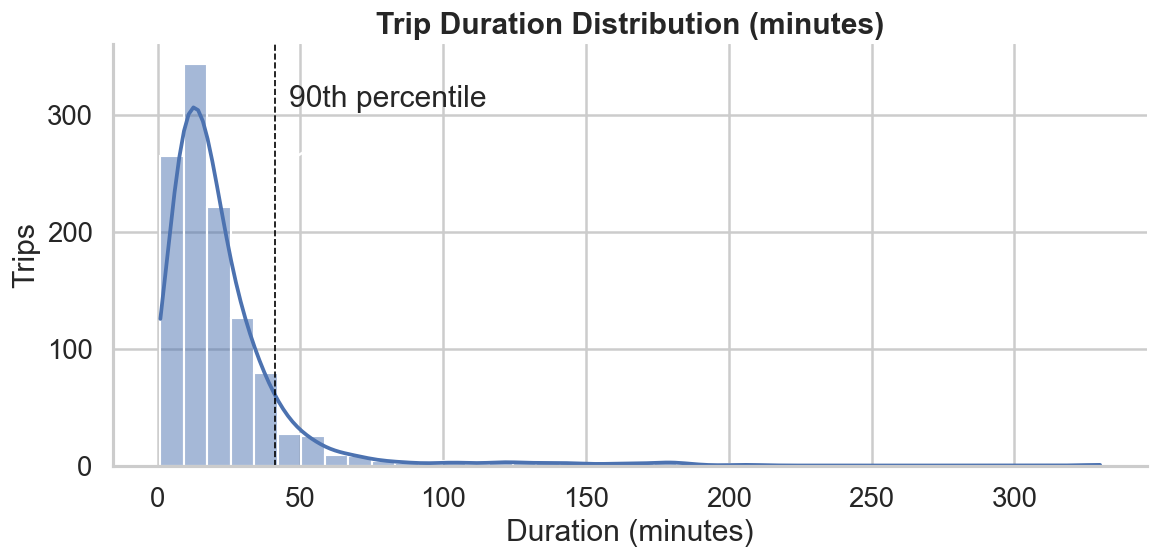

Interpretation:
- Median duration is 16.0 min; this is a better 'typical trip' KPI than mean when the tail is heavy.
- The long tail should be reviewed (airport/inter-city vs data capture issues).


In [3]:
# --- 3) Feature Engineering & Efficiency Metrics ---
work = df.copy()
work = work[(work["duration"].isna()) | (work["duration"] > 0)]
work = work[(work["MILES"].isna()) | (work["MILES"] >= 0)]

metrics = work[["MILES", "duration", "miles_per_min", "speed"]].describe(percentiles=[0.1, 0.5, 0.9]).T
display(metrics)

# Trip duration distribution (clean, annotated)
fig, ax = plt.subplots(figsize=(10, 5))
series = work["duration"].dropna()
sns.histplot(series, bins=40, kde=True, ax=ax, color=sns.color_palette()[0])
p90 = float(series.quantile(0.9))
ax.axvline(p90, linestyle="--", color="black", linewidth=1)
ax.set_title("Trip Duration Distribution (minutes)")
ax.set_xlabel("Duration (minutes)")
ax.set_ylabel("Trips")
ax.annotate("90th percentile", xy=(p90, ax.get_ylim()[1] * 0.7), xytext=(p90 + 5, ax.get_ylim()[1] * 0.85), arrowprops={"arrowstyle": "->"})
plt.tight_layout()
plt.show()

median_dur = float(series.median())
print("Interpretation:")
print(f"- Median duration is {median_dur:.1f} min; this is a better 'typical trip' KPI than mean when the tail is heavy.")
print("- The long tail should be reviewed (airport/inter-city vs data capture issues).")

Peak hour threshold (90th percentile rides/hour): 93.8
Peak day threshold  (90th percentile rides/day): 184.8


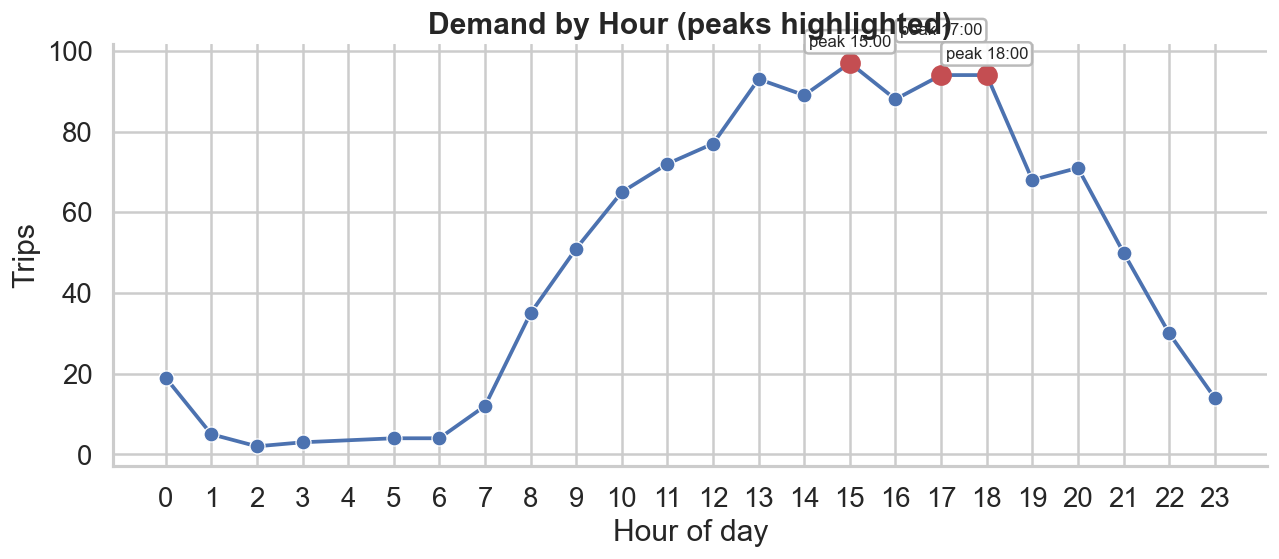

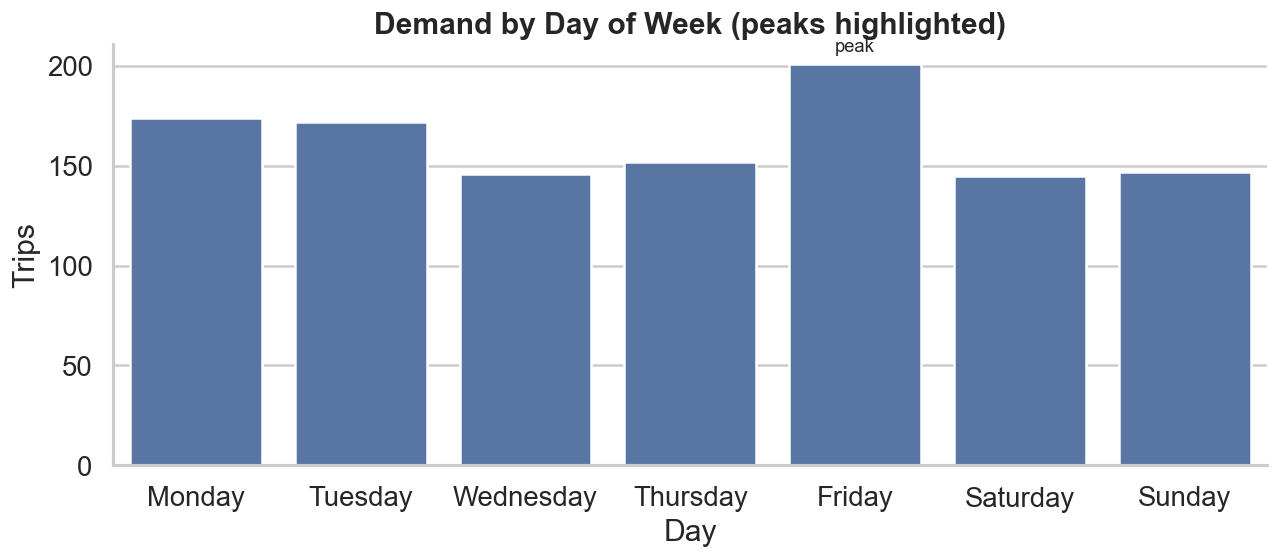

Interpretation:
- Peak hours are the most actionable for supply planning (driver positioning + incentives).
- Peak days help with weekly staffing and promo timing (commute-heavy vs weekend-heavy patterns).


In [5]:
# --- 4) Demand Peak Detection (peak hours + peak days) ---
peaks = detect_peaks(work, peak_quantile=0.9)
print("Peak hour threshold (90th percentile rides/hour):", round(peaks.hour_threshold, 2))
print("Peak day threshold  (90th percentile rides/day):", round(peaks.day_threshold, 2))

rides_by_hour = work.dropna(subset=["start_hour_int"]).groupby("start_hour_int").size().sort_index()
fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(x=rides_by_hour.index.astype(int), y=rides_by_hour.values, marker="o", ax=ax)
ax.set_title("Demand by Hour (peaks highlighted)")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Trips")
ax.set_xticks(list(range(0, 24)))

# Stagger annotations so peak labels don't overlap
for j, (hour, cnt) in enumerate(peaks.peak_hours.sort_index().items()):
    hour_i = int(hour)
    cnt_i = int(cnt)
    ax.scatter(hour_i, cnt_i, s=120, color=sns.color_palette()[3], zorder=3)
    y_offset = 10 + (j % 2) * 14
    ax.annotate(
        f"peak {hour_i}:00",
        (hour_i, cnt_i),
        textcoords="offset points",
        xytext=(0, y_offset),
        ha="center",
        fontsize=10,
        bbox={"boxstyle": "round,pad=0.25", "fc": "white", "ec": "0.7", "alpha": 0.9},
    )

plt.tight_layout()
plt.show()

rides_by_day = work.groupby("day").size().reindex(DAY_ORDER)
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(x=rides_by_day.index.astype(str), y=rides_by_day.values, ax=ax, color=sns.color_palette()[0])
ax.set_title("Demand by Day of Week (peaks highlighted)")
ax.set_xlabel("Day")
ax.set_ylabel("Trips")
for i, (day, cnt) in enumerate(rides_by_day.items()):
    if day in peaks.peak_days.index:
        ax.text(i, float(cnt) + rides_by_day.max() * 0.02, "peak", ha="center", va="bottom", fontsize=11)
plt.tight_layout()
plt.show()

print("Interpretation:")
print("- Peak hours are the most actionable for supply planning (driver positioning + incentives).")
print("- Peak days help with weekly staffing and promo timing (commute-heavy vs weekend-heavy patterns).")

,rides,miles_total,miles_median,duration_median_min,miles_per_min_median,ride_share
CATEGORY,,,,,,
Business,1062,"17,336.1",9.66,17.0,0.563,93.4%
Personal,75,"1,136.7",6.76,14.0,0.506,6.6%


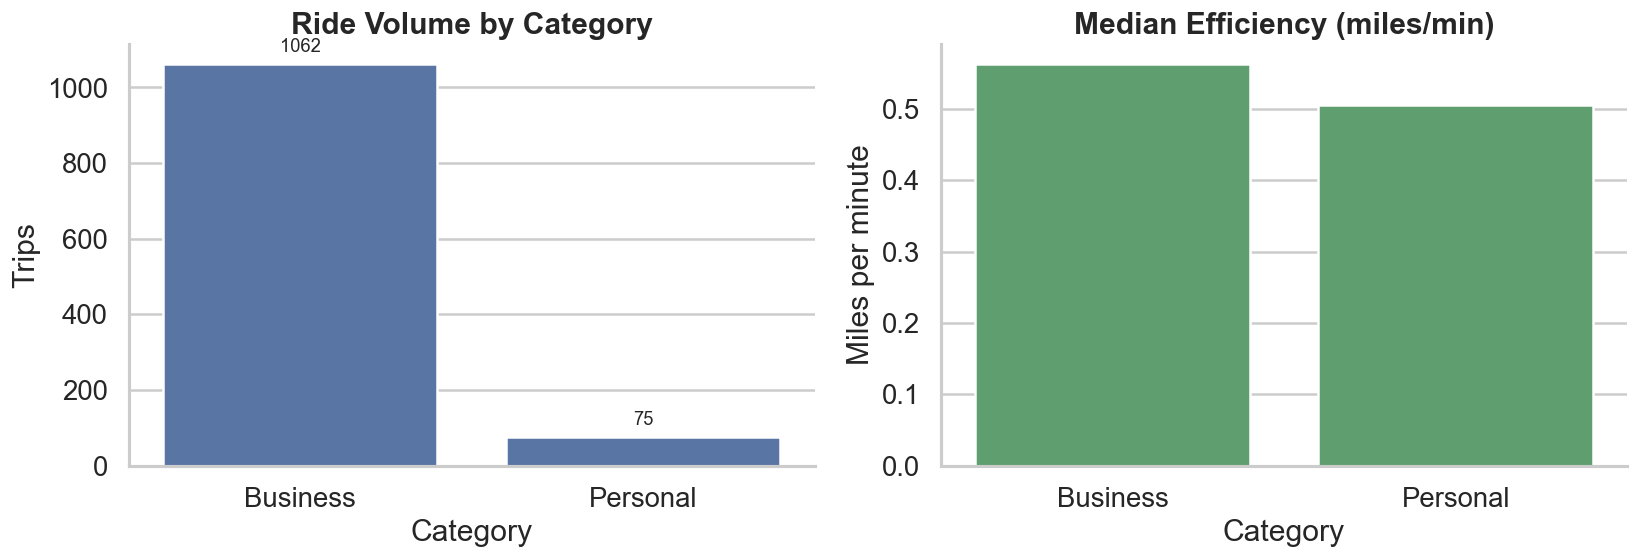

Interpretation:
- Business accounts for the largest share of rides in this dataset.
- Comparing efficiency (miles/min) helps separate 'short dense trips' from 'long flowing trips'—useful for pricing, ETAs, and driver positioning.


In [7]:
# --- 5) Category-wise Performance (Business vs Personal) ---
kpis = compute_category_kpis(work)
display(kpis.style.format({
    "miles_total": "{:,.1f}",
    "miles_median": "{:,.2f}",
    "duration_median_min": "{:,.1f}",
    "miles_per_min_median": "{:,.3f}",
    "ride_share": "{:.1%}",
}))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=kpis.index.astype(str), y=kpis["rides"], ax=axes[0], color=sns.color_palette()[0])
axes[0].set_title("Ride Volume by Category")
axes[0].set_xlabel("Category")
axes[0].set_ylabel("Trips")
for i, v in enumerate(kpis["rides"].values):
    axes[0].text(i, float(v) + kpis["rides"].max() * 0.02, f"{int(v)}", ha="center", va="bottom", fontsize=11)

sns.barplot(x=kpis.index.astype(str), y=kpis["miles_per_min_median"], ax=axes[1], color=sns.color_palette()[2])
axes[1].set_title("Median Efficiency (miles/min)")
axes[1].set_xlabel("Category")
axes[1].set_ylabel("Miles per minute")
plt.tight_layout()
plt.show()

top = kpis.index.astype(str).tolist()[0] if len(kpis) else "N/A"
print("Interpretation:")
print(f"- {top} accounts for the largest share of rides in this dataset.")
print("- Comparing efficiency (miles/min) helps separate 'short dense trips' from 'long flowing trips'—useful for pricing, ETAs, and driver positioning.")

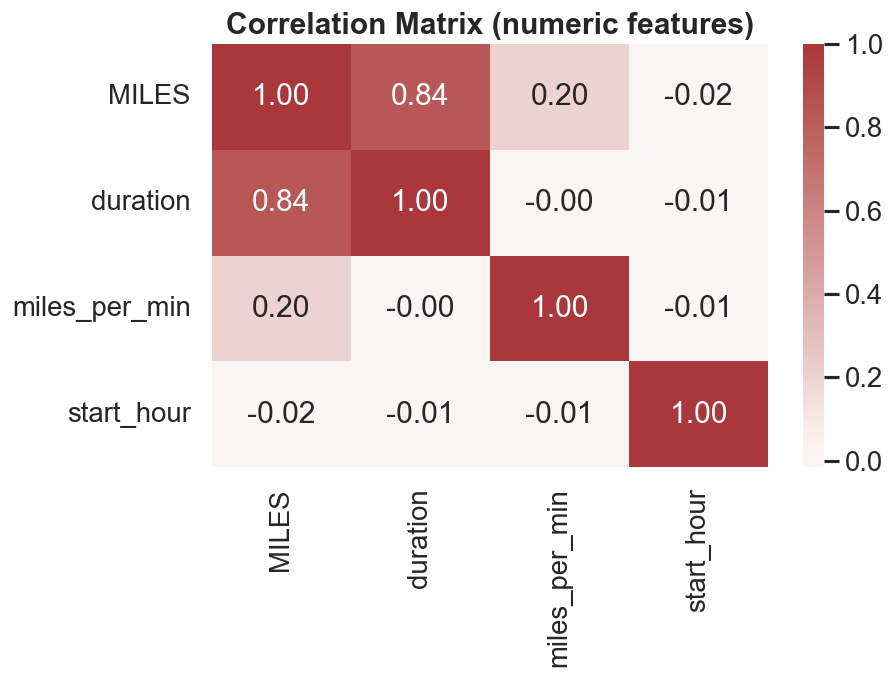

corr
MILES         duration       0.836980
duration      MILES          0.836980
MILES         miles_per_min  0.199052
miles_per_min MILES          0.199052
MILES         start_hour    -0.016075
start_hour    MILES         -0.016075
              duration      -0.012805
duration      start_hour    -0.012805
miles_per_min start_hour    -0.006563
start_hour    miles_per_min -0.006563

Interpretation:
- Miles vs duration should be strongly related; large deviations flag traffic effects or data issues.
- Efficiency (miles/min) helps separate congested short trips from smoother longer trips.


In [11]:
# --- 6) Correlation Analysis ---
corr_df = correlation_frame(work)
corr = corr_df.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Correlation Matrix (numeric features)")
plt.tight_layout()
plt.show()

# Strongest correlations (absolute), excluding self-correlation
mask = ~np.eye(corr.shape[0], dtype=bool)
pairs = (
    corr.where(mask)
    .stack()
    .rename("corr")
    .sort_values(key=lambda s: s.abs(), ascending=False)
 )
display(pairs.head(10).to_frame())

print("Interpretation:")
print("- Miles vs duration should be strongly related; large deviations flag traffic effects or data issues.")
print("- Efficiency (miles/min) helps separate congested short trips from smoother longer trips.")

Duration bounds (IQR rule): (-17.0, 55.0)
Miles/min bounds (IQR rule): (-0.1449, 1.3042)

Unusually long trips (top):


,CATEGORY,PURPOSE,START,STOP,MILES,duration,miles_per_min,speed,day,day_time,start_dt
268,Business,Customer Visit,Latta,Jacksonville,499.378202,330.0,1.513267,90.796037,Friday,Afternoon,2016-03-25 16:52:00
534,Business,Errand/Supplies,Morrisville,Banner Elk,314.304102,206.0,1.525748,91.544884,Thursday,Afternoon,2016-07-14 16:39:00
547,Personal,Commute,Boone,Cary,290.003068,185.0,1.567584,94.055049,Sunday,Morning,2016-07-17 12:20:00
867,Business,Meeting,Asheville,Mebane,315.269706,181.0,1.741822,104.509295,Sunday,Afternoon,2016-10-30 15:22:00
267,Business,Customer Visit,Cary,Latta,231.744960,178.0,1.301938,78.116279,Friday,Afternoon,2016-03-25 13:24:00
715,Business,Airport/Travel,Unknown Location,Unknown Location,252.505446,178.0,1.418570,85.114195,Saturday,Afternoon,2016-08-27 16:15:00
295,Business,Customer Visit,Jacksonville,Ridgeland,280.347028,178.0,1.574983,94.498998,Saturday,Evening,2016-04-02 19:38:00
774,Business,Temporary Site,Unknown Location,R?walpindi,28.807186,167.0,0.172498,10.349887,Thursday,Morning,2016-10-06 08:49:00
1074,Business,Meeting,Rawalpindi,Unknown Location,165.762020,166.0,0.998566,59.913983,Wednesday,Evening,2016-12-21 20:56:00
766,Business,Temporary Site,Islamabad,Islamabad,60.672118,161.0,0.376845,22.610727,Friday,Afternoon,2016-09-30 17:39:00



Unusually fast trips (top):


,CATEGORY,PURPOSE,START,STOP,MILES,duration,miles_per_min,speed,day,day_time,start_dt
773,Business,Temporary Site,Unknown Location,Unknown Location,24.301034,1.0,24.301034,1458.062040,Tuesday,Morning,2016-10-04 12:17:00
778,Business,Temporary Site,Unknown Location,Lahore,53.430088,3.0,17.810029,1068.601760,Friday,Morning,2016-10-07 10:56:00
776,Business,Temporary Site,Unknown Location,Unknown Location,29.611856,2.0,14.805928,888.355680,Thursday,Afternoon,2016-10-06 18:37:00
775,Business,Temporary Site,R?walpindi,Unknown Location,181.211684,17.0,10.659511,639.570649,Thursday,Afternoon,2016-10-06 17:23:00
791,Business,Meeting,R?walpindi,Unknown Location,29.611856,3.0,9.870619,592.237120,Wednesday,Evening,2016-10-12 19:18:00
742,Business,Temporary Site,Unknown Location,Unknown Location,15.771532,2.0,7.885766,473.145960,Sunday,Evening,2016-09-11 21:40:00
371,Business,Customer Visit,Morrisville,Raleigh,12.230984,2.0,6.115492,366.929520,Wednesday,Afternoon,2016-05-18 13:00:00
768,Business,Temporary Site,Unknown Location,Islamabad,16.898070,3.0,5.632690,337.961400,Monday,Afternoon,2016-10-03 17:09:00
120,Business,Temporary Site,Unknown Location,Unknown Location,37.819490,8.0,4.727436,283.646175,Thursday,Morning,2016-02-18 08:19:00
761,Business,Temporary Site,Unknown Location,Unknown Location,9.334172,2.0,4.667086,280.025160,Tuesday,Morning,2016-09-27 08:33:00


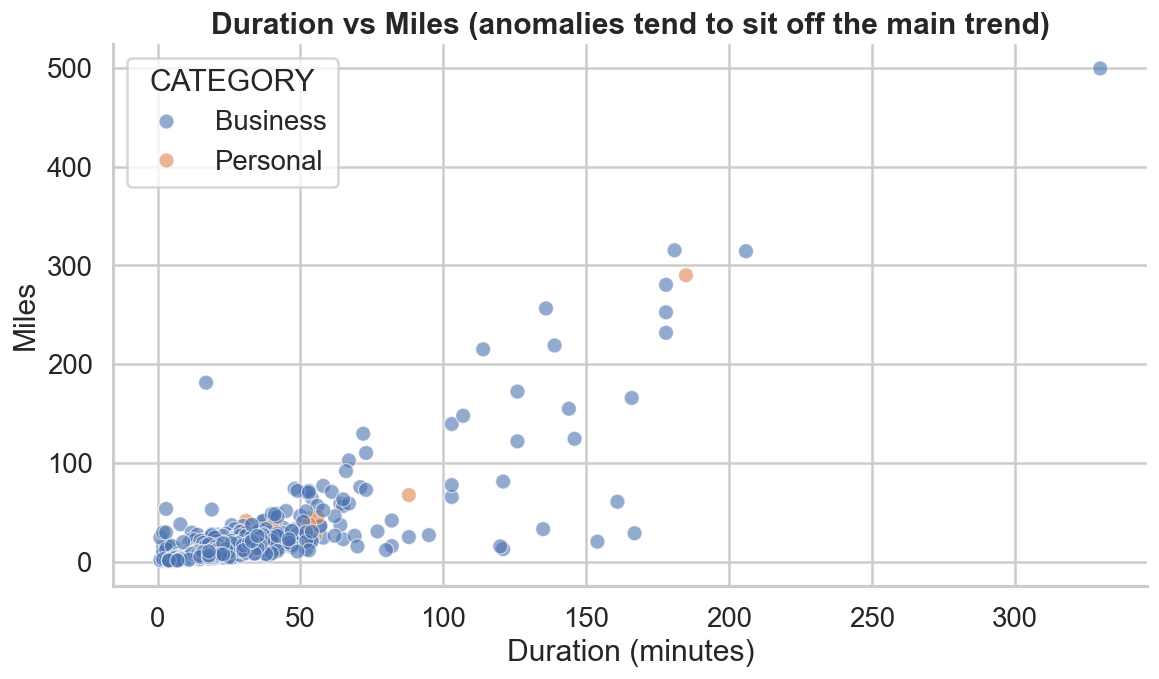

Interpretation:
- Long-duration/short-distance rides often reflect traffic or stop-heavy travel—and sometimes 'app left running'.
- Very high miles/min typically signals timestamp/GPS issues or true highway segments; either way it's QA-worthy.


In [12]:
# --- 7) Anomaly Detection (unusually long/short trips) ---
anom = detect_anomalies(work)
print("Duration bounds (IQR rule):", tuple(round(x, 2) for x in anom.duration_bounds))
print("Miles/min bounds (IQR rule):", tuple(round(x, 4) for x in anom.mpm_bounds))

cols = [c for c in ["CATEGORY","PURPOSE","START","STOP","MILES","duration","miles_per_min","speed","day","day_time","start_dt"] if c in work.columns]
print("\nUnusually long trips (top):")
display(anom.long_trips[cols])
print("\nUnusually fast trips (top):")
display(anom.very_fast[cols])

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=work, x="duration", y="MILES", hue="CATEGORY", alpha=0.6, ax=ax)
ax.set_title("Duration vs Miles (anomalies tend to sit off the main trend)")
ax.set_xlabel("Duration (minutes)")
ax.set_ylabel("Miles")
plt.tight_layout()
plt.show()

print("Interpretation:")
print("- Long-duration/short-distance rides often reflect traffic or stop-heavy travel—and sometimes 'app left running'.")
print("- Very high miles/min typically signals timestamp/GPS issues or true highway segments; either way it's QA-worthy.")

,rides,miles_total,duration_total_min
start_dt,,,
2016-01-01,61,825.430486,1116.0
2016-02-01,114,1457.257370,2249.0
2016-03-01,112,2402.583686,2744.0
2016-04-01,53,1559.450460,1580.0
2016-05-01,48,564.717406,703.0
2016-06-01,103,1276.689422,2071.0


,rides,miles_total,duration_total_min
start_dt,,,
2016-01-04,3,23.979166,31.0
2016-01-11,14,227.721610,301.0
2016-01-18,15,183.947562,294.0
2016-01-25,8,148.381148,165.0
2016-02-01,24,316.396244,409.0
2016-02-08,21,203.903378,335.0


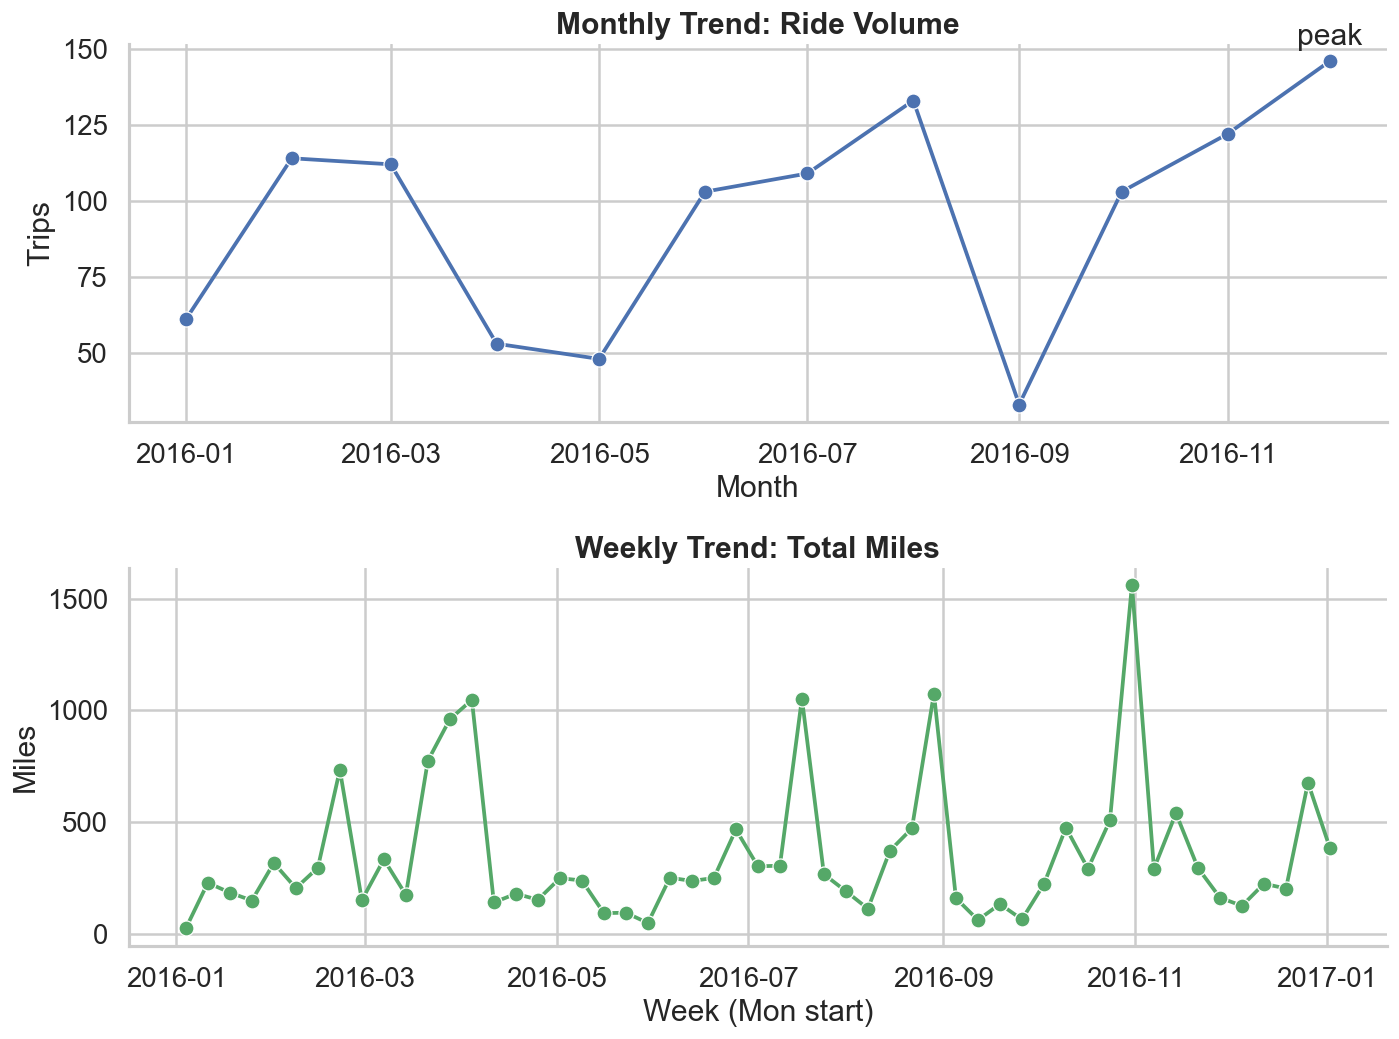

Interpretation:
- Watch for weeks where miles spike without a matching ride spike: fewer, longer trips drive distance and cost differently.
- If ride volume rises while efficiency falls, growth may be coming from more congested corridors—optimize pickup and routing guidance.


In [13]:
# --- 8) Trend Analysis (monthly + weekly) ---
monthly, weekly = monthly_weekly_trends(work)
display(monthly.head(6))
display(weekly.head(6))

fig, axes = plt.subplots(2, 1, figsize=(12, 9))
sns.lineplot(x=monthly.index, y=monthly["rides"], marker="o", ax=axes[0])
axes[0].set_title("Monthly Trend: Ride Volume")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Trips")
if len(monthly):
    peak_month = monthly["rides"].idxmax()
    axes[0].annotate("peak", xy=(peak_month, float(monthly.loc[peak_month, "rides"])), textcoords="offset points", xytext=(0, 10), ha="center")

sns.lineplot(x=weekly.index, y=weekly["miles_total"], marker="o", ax=axes[1], color=sns.color_palette()[2])
axes[1].set_title("Weekly Trend: Total Miles")
axes[1].set_xlabel("Week (Mon start)")
axes[1].set_ylabel("Miles")
plt.tight_layout()
plt.show()

print("Interpretation:")
print("- Watch for weeks where miles spike without a matching ride spike: fewer, longer trips drive distance and cost differently.")
print("- If ride volume rises while efficiency falls, growth may be coming from more congested corridors—optimize pickup and routing guidance.")

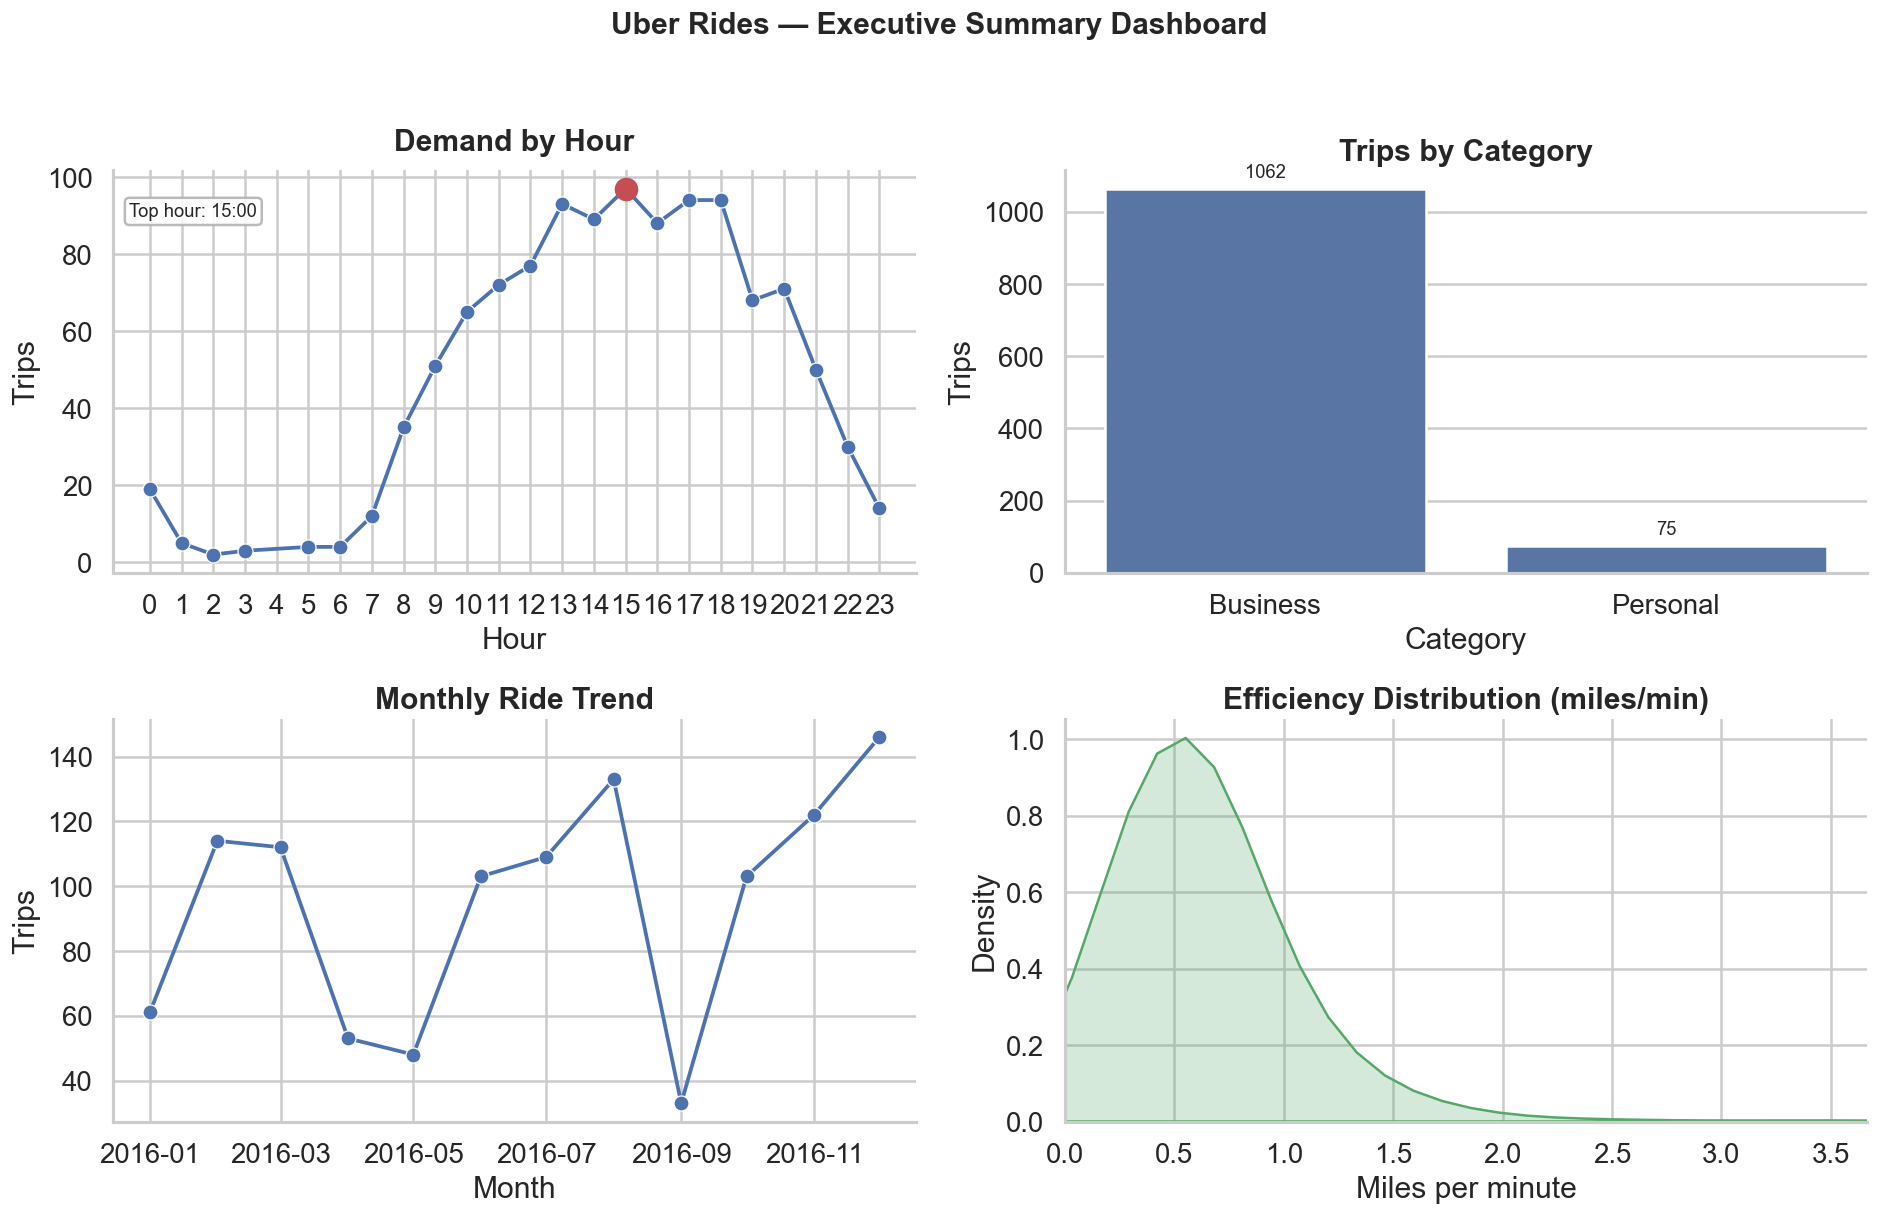

Dashboard readout:
- Busiest hour: 15:00 (97 trips)
- Busiest day: Friday (201 trips)
- Use this view to align staffing (peaks) with service quality (efficiency) and demand trend (growth/decline).


In [15]:
# --- 9) Dashboard-style summary (single stakeholder-ready view) ---
rides_by_hour = work.dropna(subset=["start_hour_int"]).groupby("start_hour_int").size().sort_index()
rides_by_day = work.groupby("day").size().reindex(DAY_ORDER)
cat_counts = work["CATEGORY"].value_counts(dropna=False)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle("Uber Rides — Executive Summary Dashboard", y=1.02, fontsize=18, fontweight="bold")

# (1) Hourly demand + top hour
ax = axes[0, 0]
sns.lineplot(x=rides_by_hour.index.astype(int), y=rides_by_hour.values, marker="o", ax=ax)
ax.set_title("Demand by Hour", pad=12)
ax.set_xlabel("Hour")
ax.set_ylabel("Trips")
ax.set_xticks(list(range(0, 24)))
if len(rides_by_hour):
    top_hour = int(rides_by_hour.idxmax())
    top_cnt = int(rides_by_hour.max())
    ax.scatter(top_hour, top_cnt, s=160, color=sns.color_palette()[3], zorder=3)
    ax.text(0.02, 0.92, f"Top hour: {top_hour}:00", transform=ax.transAxes, fontsize=11, ha="left", va="top", bbox={"boxstyle": "round,pad=0.25", "fc": "white", "ec": "0.7", "alpha": 0.9})

# (2) Category split
ax = axes[0, 1]
sns.barplot(x=cat_counts.index.astype(str), y=cat_counts.values, ax=ax, color=sns.color_palette()[0])
ax.set_title("Trips by Category")
ax.set_xlabel("Category")
ax.set_ylabel("Trips")
for i, v in enumerate(cat_counts.values):
    ax.text(i, float(v) + cat_counts.max() * 0.02, f"{int(v)}", ha="center", va="bottom", fontsize=11)

# (3) Monthly rides
ax = axes[1, 0]
sns.lineplot(x=monthly.index, y=monthly["rides"], marker="o", ax=ax)
ax.set_title("Monthly Ride Trend")
ax.set_xlabel("Month")
ax.set_ylabel("Trips")

# (4) Efficiency distribution (zoomed to typical range)
ax = axes[1, 1]
mpm = work["miles_per_min"].dropna()
sns.kdeplot(mpm, fill=True, ax=ax, color=sns.color_palette()[2])
ax.set_title("Efficiency Distribution (miles/min)")
ax.set_xlabel("Miles per minute")
ax.set_ylabel("Density")
if len(mpm):
    p99 = float(mpm.quantile(0.99))
    ax.set_xlim(0, max(p99, 0.5))

plt.tight_layout()
plt.show()

print("Dashboard readout:")
if len(rides_by_hour):
    print(f"- Busiest hour: {top_hour}:00 ({top_cnt} trips)")
if len(rides_by_day.dropna()):
    d = rides_by_day.idxmax()
    print(f"- Busiest day: {d} ({int(rides_by_day.max())} trips)")
print("- Use this view to align staffing (peaks) with service quality (efficiency) and demand trend (growth/decline).")

## 10) Business Recommendations (grounded in the signals above)

- Use **peak hours** to drive supply incentives and reduce pickup time (fastest operational win).
- Track **median duration** and **median miles/min** per category to measure congestion/pickup friction changes without being distorted by outliers.
- Review anomaly tables monthly: they often reveal **data quality issues** *and* a small set of repeatable operational edge-cases (multi-stop rides, airport corridors).
- Watch **weekly miles** alongside **ride counts**: miles is closer to cost/revenue impact than ride volume alone.